# Publication figure: XAI fidelity deletion curves

Notebook ini membaca langsung `fidelity_curve_summary.csv` hasil evaluasi. Figure membandingkan **Baseline** (`cv_resnet50`) dengan **Proposed** (`multistage_direct_guided_cv_resnet50`) pada medium Gaussian blur ($\sigma=5$, kernel $31\times31$).

Dua figure dibuat:

1. **Absolute probability** untuk menampilkan Deletion AUC utama.
2. **Relative probability** untuk perbandingan lintas model yang lebih adil ketika probability awal berbeda.

Setiap titik merupakan macro mean antar-nodule. Nilai yang turun lebih cepat menunjukkan fidelity yang lebih baik.

In [1]:
from pathlib import Path

from IPython.display import Image, display
import matplotlib.pyplot as plt
from matplotlib import font_manager
import pandas as pd


# Notebook dapat dijalankan dari root repository atau dari 004_evaluation.
working_directory = Path.cwd().resolve()
if (working_directory / "experiment_results").is_dir():
    project_root = working_directory
else:
    project_root = working_directory.parent

experiment_id = "fa028196-fd4c-441f-a5d3-3efb9707e7f9"
fidelity_root = (
    project_root
    / "experiment_results"
    / experiment_id
    / "evaluation"
    / "xai_fidelity"
)
output_directory = project_root / "004_evaluation" / "fidelity_figures"
output_directory.mkdir(parents=True, exist_ok=True)

model_labels = {
    "cv_resnet50": "Baseline",
    "multistage_direct_guided_cv_resnet50": "Proposed",
}

# Gunakan Times New Roman jika tersedia. Tinos adalah pengganti yang
# metric-compatible dan memiliki tampilan sangat dekat dengan Times.
tinos_path = Path("/usr/share/fonts/truetype/croscore/Tinos-Regular.ttf")
if tinos_path.is_file():
    font_manager.fontManager.addfont(tinos_path)

available_fonts = {font.name for font in font_manager.fontManager.ttflist}
font_candidates = ["Times New Roman", "Tinos", "Liberation Serif"]
font_family = next(
    (font for font in font_candidates if font in available_fonts),
    "serif",
)

plt.rcParams.update(
    {
        "font.family": font_family,
        "font.size": 8,
        "axes.labelsize": 8,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "axes.facecolor": "white",
        "figure.facecolor": "white",
        "savefig.facecolor": "white",
    }
)

print(f"Project root : {project_root}")
print(f"Data root    : {fidelity_root}")
print(f"Output       : {output_directory}")
print(f"Font         : {font_family}")

Project root : /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai
Data root    : /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/experiment_results/fa028196-fd4c-441f-a5d3-3efb9707e7f9/evaluation/xai_fidelity
Output       : /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/004_evaluation/fidelity_figures
Font         : Tinos


In [2]:
# Baca curve summary kedua model.
frames = []
for model_name, display_name in model_labels.items():
    csv_path = fidelity_root / model_name / "fidelity_curve_summary.csv"
    if not csv_path.is_file():
        raise FileNotFoundError(f"CSV tidak ditemukan: {csv_path}")

    model_frame = pd.read_csv(csv_path)
    model_frame = model_frame[model_frame["blur_name"].eq("medium")].copy()
    model_frame["display_model"] = display_name
    frames.append(model_frame)

curves = pd.concat(frames, ignore_index=True)
curves = curves.sort_values(
    ["xai_method", "layer", "display_model", "deletion_percent"]
).reset_index(drop=True)

expected_rows = 2 * 2 * 4 * 7  # model × method × layer × deletion point
if len(curves) != expected_rows:
    raise ValueError(
        f"Jumlah baris tidak sesuai: {len(curves)}; seharusnya {expected_rows}."
    )

print(f"Rows loaded  : {len(curves)}")
print(f"Nodules      : {int(curves['number_of_nodules'].max())}")
curves.head()

Rows loaded  : 112
Nodules      : 203


,model,xai_method,layer,blur_name,blur_sigma,blur_kernel_size,deletion_percent,number_of_nodules,mean_target_probability,std_target_probability,mean_relative_probability,std_relative_probability,display_model
0,cv_resnet50,gradcam,layer1,medium,5.0,31,0.0,203,0.640523,0.079286,1.000000,0.000000,Baseline
1,cv_resnet50,gradcam,layer1,medium,5.0,31,5.0,203,0.590823,0.095570,0.924501,0.104216,Baseline
2,cv_resnet50,gradcam,layer1,medium,5.0,31,10.0,203,0.551686,0.100220,0.863103,0.114234,Baseline
3,cv_resnet50,gradcam,layer1,medium,5.0,31,20.0,203,0.524067,0.097968,0.821068,0.115303,Baseline
4,cv_resnet50,gradcam,layer1,medium,5.0,31,30.0,203,0.516764,0.098920,0.810022,0.121166,Baseline


In [3]:
# Visual style that remains distinguishable in grayscale.
line_styles = {
    "Baseline": {
        "color": "#0072B2",
        "linestyle": "-",
        "marker": "o",
    },
    "Proposed": {
        "color": "#D55E00",
        "linestyle": "--",
        "marker": "s",
    },
}

method_labels = {"gradcam": "Grad-CAM", "lrp": "LRP"}
methods = ["gradcam", "lrp"]
layers = ["layer1", "layer2", "layer3", "layer4"]
panel_letters = list("abcdefgh")


def create_deletion_figure(y_column, y_label, output_name):
    """Create one clean 2-by-4 comparison figure."""

    figure, axes = plt.subplots(
        nrows=2,
        ncols=4,
        figsize=(7.16, 3.85),
        sharex=True,
        sharey=True,
    )

    y_min = float(curves[y_column].min())
    y_max = float(curves[y_column].max())
    y_padding = max(0.02, (y_max - y_min) * 0.08)

    panel_index = 0
    for row_index, method in enumerate(methods):
        for column_index, layer in enumerate(layers):
            axis = axes[row_index, column_index]
            panel = curves[
                curves["xai_method"].eq(method)
                & curves["layer"].eq(layer)
            ]

            for display_name in ["Baseline", "Proposed"]:
                model_curve = panel[
                    panel["display_model"].eq(display_name)
                ].sort_values("deletion_percent")
                style = line_styles[display_name]

                axis.plot(
                    model_curve["deletion_percent"],
                    model_curve[y_column],
                    label=display_name,
                    color=style["color"],
                    linestyle=style["linestyle"],
                    marker=style["marker"],
                    linewidth=1.25,
                    markersize=3.2,
                    markerfacecolor="white",
                    markeredgewidth=0.8,
                )

            layer_number = layer.replace("layer", "")
            panel_label = (
                f"({panel_letters[panel_index]}) "
                f"{method_labels[method]}, L{layer_number}"
            )
            axis.text(
                0.04,
                0.95,
                panel_label,
                transform=axis.transAxes,
                horizontalalignment="left",
                verticalalignment="top",
                fontsize=8,
            )
            panel_index += 1

            axis.set_xlim(-1, 51)
            axis.set_ylim(y_min - y_padding, y_max + y_padding)
            axis.set_xticks([0, 10, 20, 30, 40, 50])
            axis.grid(
                True,
                which="major",
                color="#D0D0D0",
                linewidth=0.35,
            )
            axis.spines["top"].set_visible(False)
            axis.spines["right"].set_visible(False)
            axis.spines["left"].set_linewidth(0.6)
            axis.spines["bottom"].set_linewidth(0.6)
            axis.tick_params(width=0.6, length=2.5)

    handles, labels = axes[0, 0].get_legend_handles_labels()
    figure.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.995),
        ncol=2,
        frameon=False,
        handlelength=2.6,
        columnspacing=1.6,
    )
    figure.supxlabel("Deleted Attribution (%)", fontsize=8, y=0.025)
    figure.supylabel(y_label, fontsize=8, x=0.015)
    figure.subplots_adjust(
        left=0.085,
        right=0.995,
        bottom=0.14,
        top=0.89,
        wspace=0.12,
        hspace=0.18,
    )

    output_path = output_directory / output_name
    figure.savefig(
        output_path,
        dpi=600,
        bbox_inches="tight",
        pad_inches=0.03,
        facecolor="white",
    )
    plt.close(figure)
    return output_path

In [4]:
absolute_figure = create_deletion_figure(
    y_column="mean_target_probability",
    y_label="Target-Class Probability",
    output_name="fidelity_deletion_curves_absolute_medium_blur.png",
)

relative_figure = create_deletion_figure(
    y_column="mean_relative_probability",
    y_label="Relative Target-Class Probability",
    output_name="fidelity_deletion_curves_relative_medium_blur.png",
)

print(f"Absolute figure: {absolute_figure}")
print(f"Relative figure: {relative_figure}")

Absolute figure: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/004_evaluation/fidelity_figures/fidelity_deletion_curves_absolute_medium_blur.png
Relative figure: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/004_evaluation/fidelity_figures/fidelity_deletion_curves_relative_medium_blur.png


In [5]:
# Figure ringkas untuk paper: Grad-CAM dan LRP disimpan terpisah.
# Angka pada legend di dalam area grafik adalah absolute Deletion AUC.
auc_path = fidelity_root / "fidelity_primary_medium_blur_combined.csv"
auc_frame = pd.read_csv(auc_path)
auc_frame = auc_frame[auc_frame["blur_name"].eq("medium")].copy()
auc_frame["display_model"] = auc_frame["model"].map(model_labels)

layer_styles = {
    "layer1": {"color": "#000000", "marker": "o"},
    "layer2": {"color": "#0067C5", "marker": "s"},
    "layer3": {"color": "#E66100", "marker": "^"},
    "layer4": {"color": "#7B2CBF", "marker": "D"},
}
model_styles = {
    "Baseline": {"short": "B", "linestyle": "-"},
    "Proposed": {"short": "P", "linestyle": "--"},
}


def create_separate_absolute_figures():
    """Save Grad-CAM and LRP as two independent figures."""

    y_column = "mean_target_probability"
    y_min = float(curves[y_column].min())
    y_max = float(curves[y_column].max())
    y_padding = max(0.02, (y_max - y_min) * 0.08)

    output_paths = {}

    for method in methods:
        figure, axis = plt.subplots(figsize=(3.55, 3.20))

        for layer in layers:
            layer_number = layer.replace("layer", "")
            layer_style = layer_styles[layer]

            for display_name in ["Baseline", "Proposed"]:
                model_style = model_styles[display_name]
                model_curve = curves[
                    curves["xai_method"].eq(method)
                    & curves["layer"].eq(layer)
                    & curves["display_model"].eq(display_name)
                ].sort_values("deletion_percent")

                auc_row = auc_frame[
                    auc_frame["xai_method"].eq(method)
                    & auc_frame["layer"].eq(layer)
                    & auc_frame["display_model"].eq(display_name)
                ]
                if len(auc_row) != 1:
                    raise ValueError(
                        f"AUC row tidak unik: {method}, {layer}, {display_name}"
                    )
                auc_value = float(
                    auc_row.iloc[0]["mean_deletion_auc_across_nodules"]
                )
                legend_label = (
                    f"{model_style['short']}-L{layer_number} "
                    f"({auc_value:.3f})"
                )

                axis.plot(
                    model_curve["deletion_percent"],
                    model_curve[y_column],
                    label=legend_label,
                    color=layer_style["color"],
                    linestyle=model_style["linestyle"],
                    marker=layer_style["marker"],
                    linewidth=1.25,
                    markersize=3.2,
                    markerfacecolor=(
                        "white"
                        if display_name == "Baseline"
                        else layer_style["color"]
                    ),
                    markeredgewidth=0.8,
                )

        axis.set_xlim(-1, 51)
        axis.set_ylim(y_min - y_padding, y_max + y_padding)
        axis.set_xticks([0, 10, 20, 30, 40, 50])
        axis.set_xlabel("Deleted Attribution (%)", fontsize=8)
        axis.set_ylabel("Target-Class Probability", fontsize=8)
        axis.grid(
            True,
            which="major",
            color="#D0D0D0",
            linewidth=0.35,
        )
        for spine in axis.spines.values():
            spine.set_visible(True)
            spine.set_color("#000000")
            spine.set_linewidth(0.6)
        axis.tick_params(width=0.6, length=2.5)
        axis.legend(
            loc="upper right",
            ncol=2,
            frameon=True,
            facecolor="white",
            edgecolor="#B0B0B0",
            framealpha=0.92,
            fontsize=6.5,
            title="Model-Layer (AUC)",
            title_fontsize=7,
            handlelength=2.2,
            columnspacing=0.7,
            handletextpad=0.4,
            labelspacing=0.35,
        )
        figure.subplots_adjust(
            left=0.18,
            right=0.985,
            bottom=0.16,
            top=0.985,
        )

        output_path = (
            output_directory
            / f"fidelity_deletion_curve_absolute_{method}_auc_medium_blur.png"
        )
        figure.savefig(
            output_path,
            dpi=600,
            bbox_inches="tight",
            pad_inches=0.03,
            facecolor="white",
        )
        plt.close(figure)
        output_paths[method] = output_path

    return output_paths


separate_figures = create_separate_absolute_figures()
for method, output_path in separate_figures.items():
    print(f"{method_labels[method]} figure: {output_path}")

Grad-CAM figure: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/004_evaluation/fidelity_figures/fidelity_deletion_curve_absolute_gradcam_auc_medium_blur.png
LRP figure: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/004_evaluation/fidelity_figures/fidelity_deletion_curve_absolute_lrp_auc_medium_blur.png


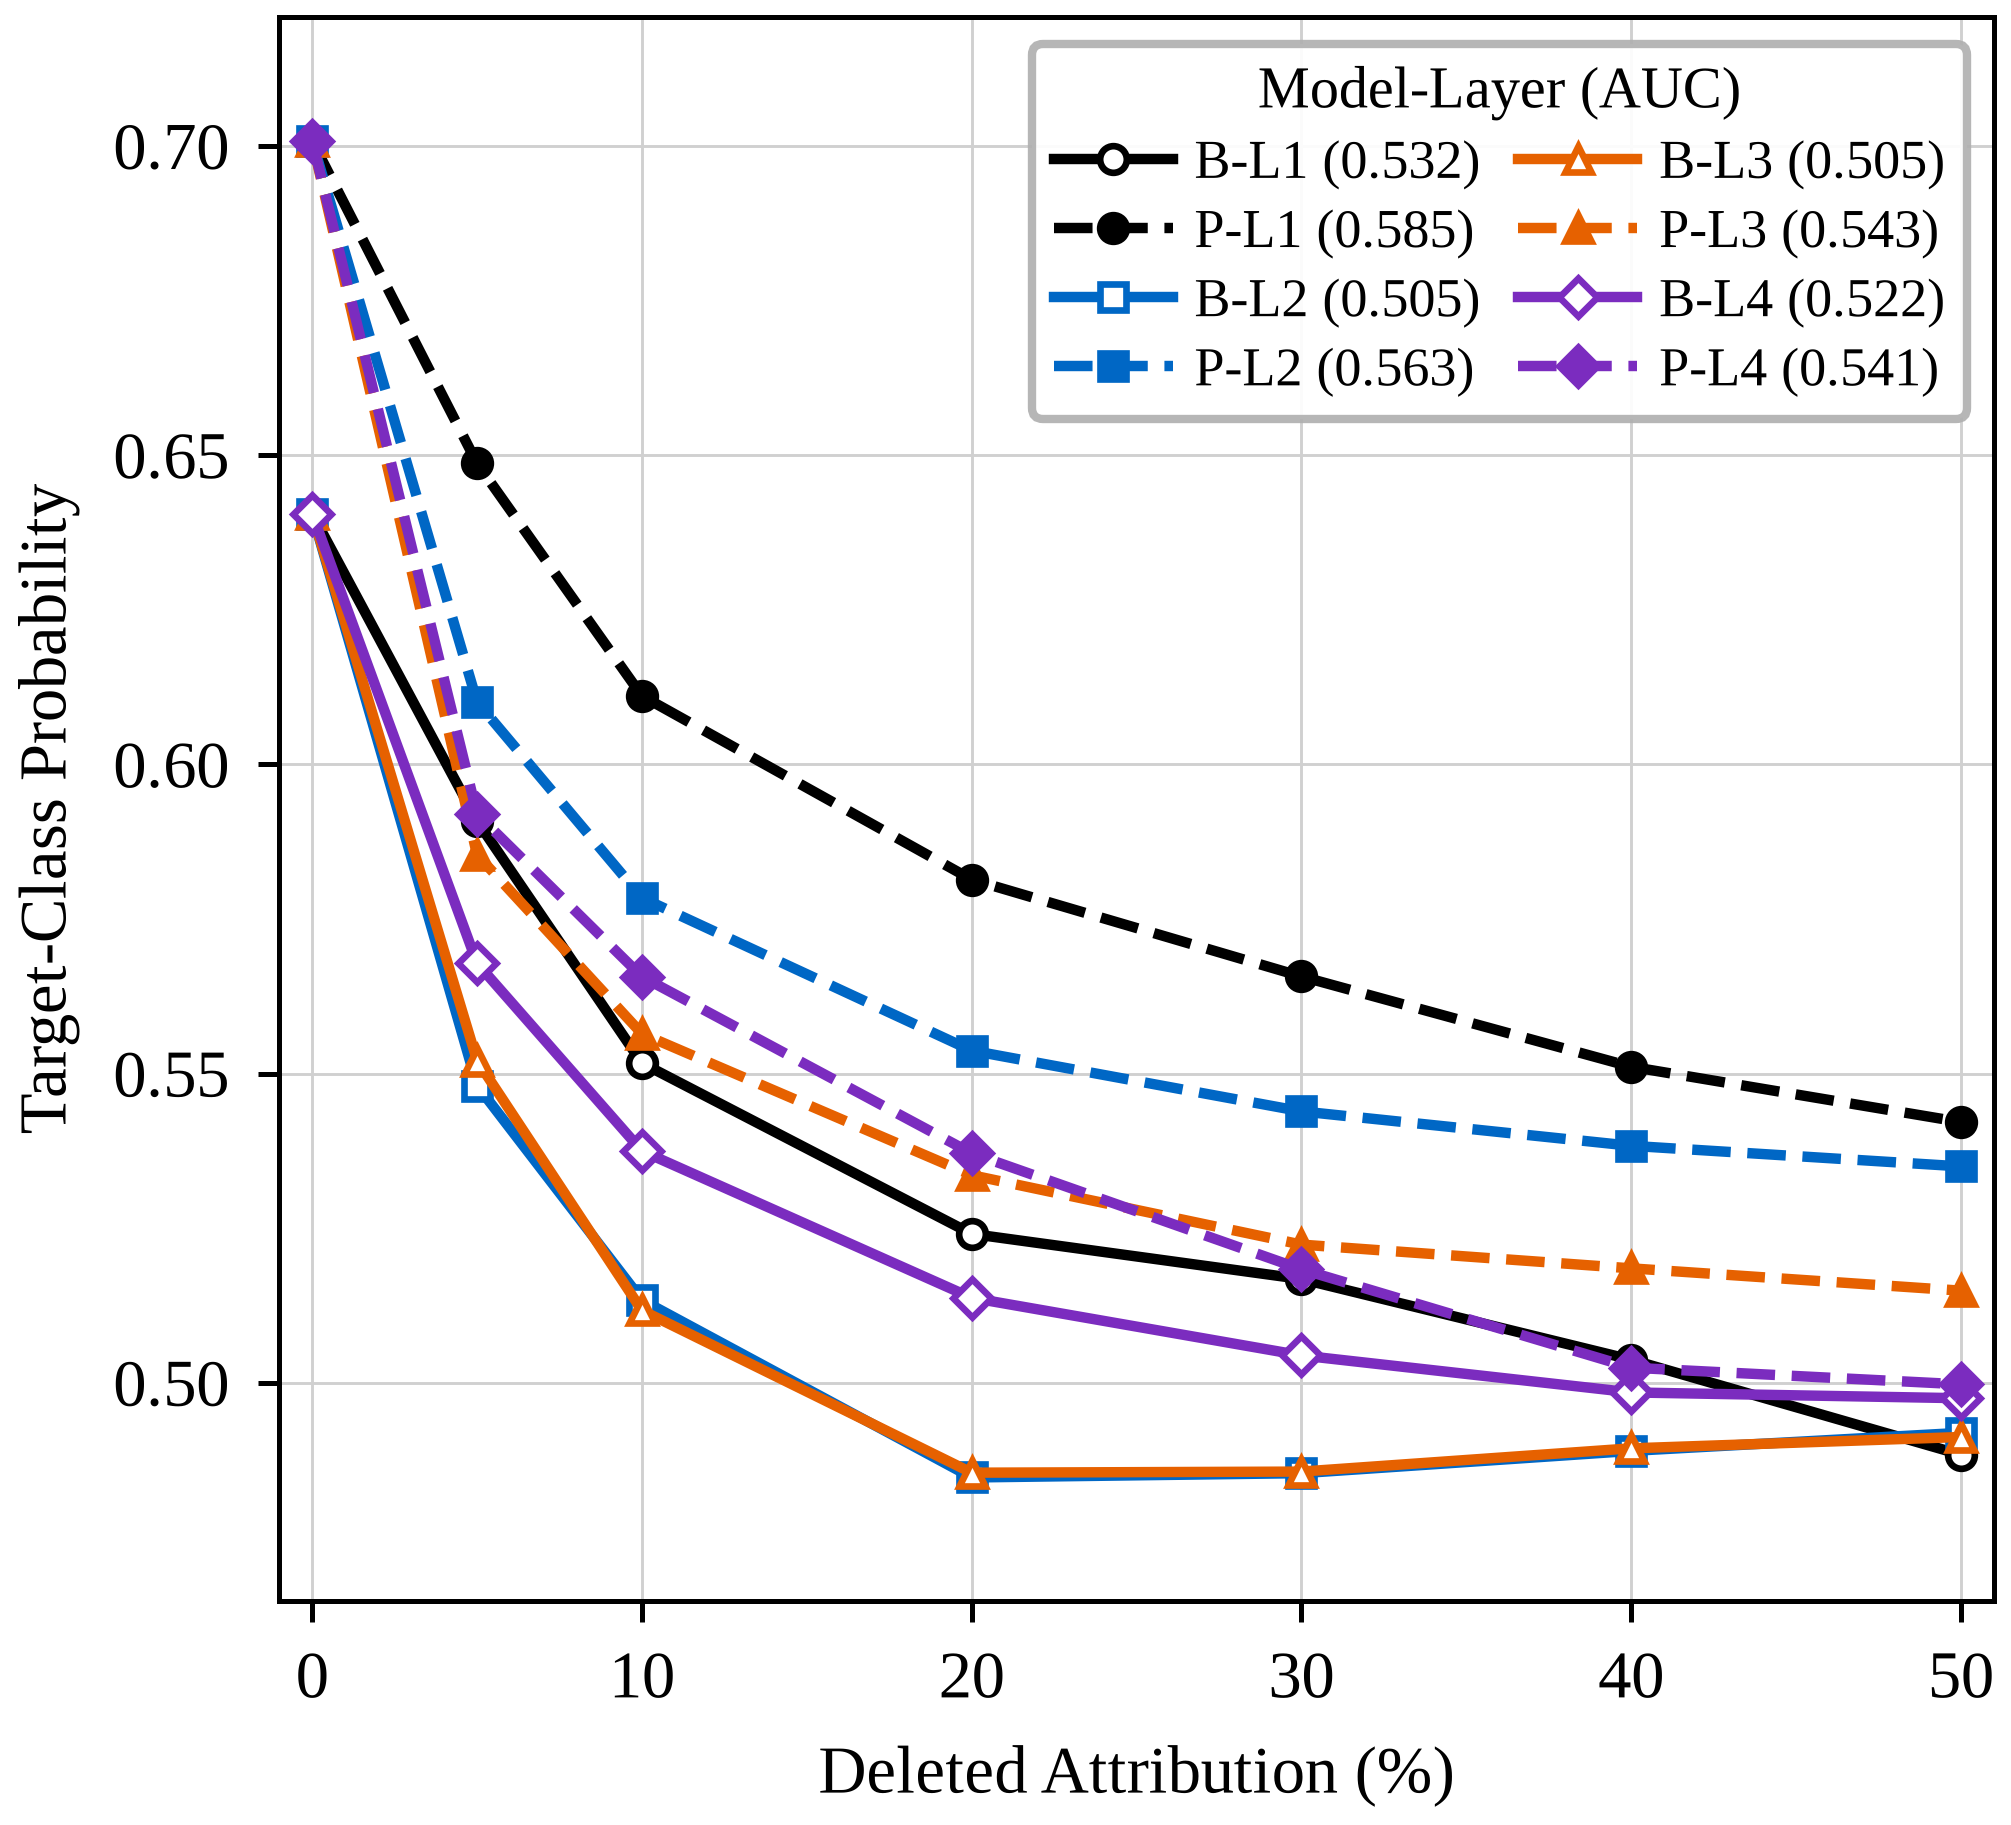

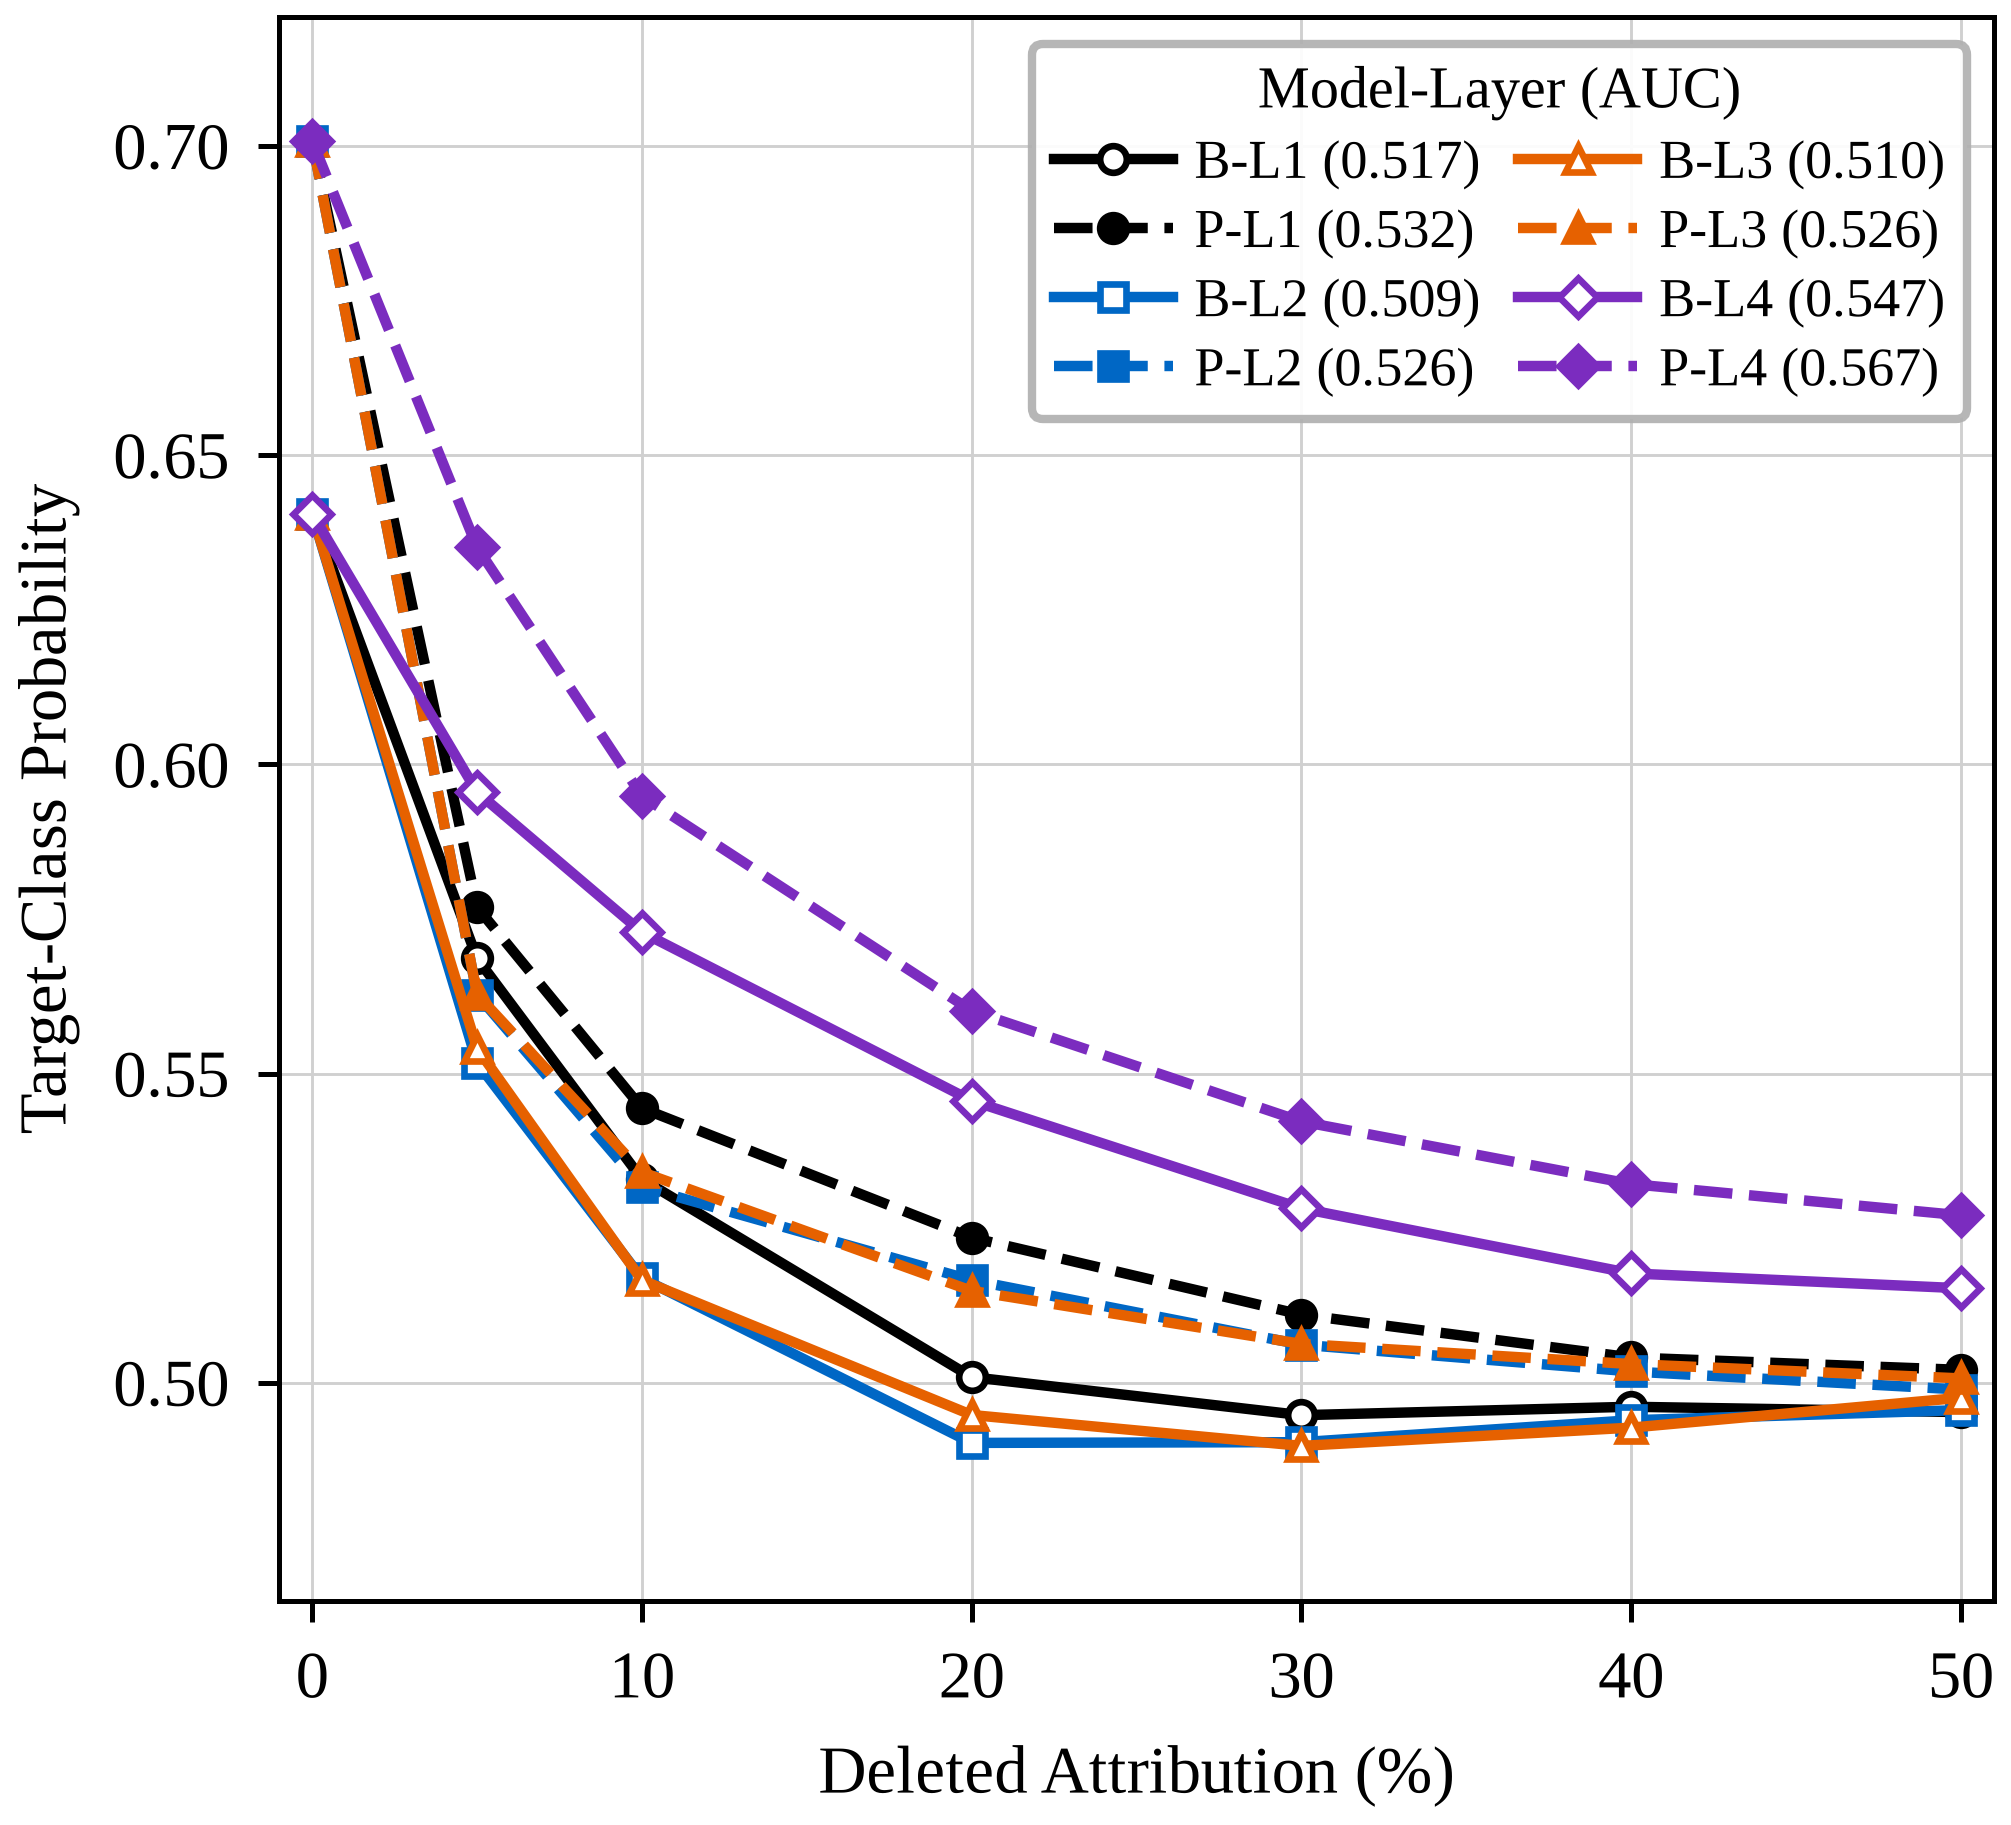

In [6]:
# Preview kedua figure. Setiap PNG disimpan secara terpisah pada 600 dpi.
for method in methods:
    display(Image(filename=str(separate_figures[method]), width=600))

## Suggested figure captions

**Absolute figure.** *Deletion curves for Grad-CAM and LRP across ResNet-50 layers under medium Gaussian blur ($\sigma=5$, kernel $31\times31$). Curves show the nodule-macro mean target-class probability after cumulatively replacing pixels with the highest attribution scores. A faster probability decrease indicates better explanation fidelity.*

**Relative figure.** *Relative deletion curves for Grad-CAM and LRP across ResNet-50 layers under medium Gaussian blur ($\sigma=5$, kernel $31\times31$). Target-class probabilities are normalized by their corresponding unperturbed probabilities to account for differences in initial model confidence. A faster decrease indicates better relative fidelity.*

**Separate absolute figures.** *Absolute deletion curves under medium Gaussian blur ($\sigma=5$, kernel $31\times31$). Each figure combines Layer 1--4 for the baseline (B, solid lines) and proposed direct-guided model (P, dashed lines). Values in parentheses report the nodule-macro mean Deletion AUC; lower values indicate better absolute fidelity.*

## Plausibility comparison at IoU@10%

The following table is generated directly from the plausibility evaluation CSV files for the baseline and multistage direct-guided models. The reported IoU is the **mean IoU across nodules** at the top 10% attribution threshold.

Nodule coverage is calculated for each slice as:

$$\mathrm{Nodule\ Coverage}=\frac{\mathrm{intersection\ pixels}}{\mathrm{ground\ truth\ pixels}}$$

Slice-level coverage is first averaged within each nodule and then averaged across nodules. The DG change is calculated as **Proposed minus Baseline**. A positive change indicates a higher value for the direct-guided model. Coverage changes are reported in percentage points (p.p.).

In [7]:
# Lokasi hasil plausibility yang sudah dihasilkan oleh program evaluasi.
plausibility_root = (
    project_root
    / "experiment_results"
    / experiment_id
    / "evaluation"
    / "xai_plausibility"
)

plausibility_models = {
    "Baseline": "cv_resnet50",
    "Proposed": "multistage_direct_guided_cv_resnet50",
}

model_metrics = {}
iou_validation_errors = {}

for display_name, model_directory in plausibility_models.items():
    model_root = plausibility_root / model_directory

    # CSV primary berisi mean IoU antar-nodule pada top 10%.
    primary_path = model_root / "plausibility_primary_iou_at_10.csv"
    primary = pd.read_csv(primary_path)
    primary = primary[primary["top_k_percent"].eq(10)].copy()

    # CSV slice menyediakan intersection dan ukuran ground-truth mask.
    slice_path = model_root / "plausibility_slice.csv"
    slice_data = pd.read_csv(slice_path)
    slice_data = slice_data[slice_data["top_k_percent"].eq(10)].copy()

    if primary.empty or slice_data.empty:
        raise ValueError(f"Data IoU@10% tidak ditemukan untuk {display_name}.")
    if slice_data["ground_truth_pixels"].le(0).any():
        raise ValueError(
            f"Ground-truth mask kosong ditemukan untuk {display_name}."
        )

    slice_data["slice_nodule_coverage"] = (
        slice_data["intersection_pixels"]
        / slice_data["ground_truth_pixels"]
    )

    # Hindari nodule dengan banyak slice mendominasi hasil.
    nodule_metrics = (
        slice_data.groupby(
            ["xai_method", "layer", "nodule_id"],
            as_index=False,
        )
        .agg(
            nodule_iou=("iou", "mean"),
            nodule_coverage=("slice_nodule_coverage", "mean"),
        )
    )

    derived = (
        nodule_metrics.groupby(["xai_method", "layer"], as_index=False)
        .agg(
            derived_mean_iou=("nodule_iou", "mean"),
            mean_nodule_coverage=("nodule_coverage", "mean"),
            derived_number_of_nodules=("nodule_id", "nunique"),
        )
    )

    metrics = primary.merge(
        derived,
        on=["xai_method", "layer"],
        how="inner",
        validate="one_to_one",
    )

    # Validasi bahwa agregasi ulang dari CSV slice sama dengan CSV primary.
    maximum_iou_error = (
        metrics["mean_iou_across_nodules"]
        - metrics["derived_mean_iou"]
    ).abs().max()
    iou_validation_errors[display_name] = maximum_iou_error
    if maximum_iou_error > 1e-8:
        raise ValueError(
            f"Agregasi IoU {display_name} tidak cocok dengan CSV primary."
        )
    if not (
        metrics["number_of_nodules"]
        == metrics["derived_number_of_nodules"]
    ).all():
        raise ValueError(
            f"Jumlah nodule {display_name} tidak cocok antar-CSV."
        )

    model_metrics[display_name] = metrics.set_index(
        ["xai_method", "layer"]
    )

# Susun tabel dalam urutan Grad-CAM/LRP dan Layer 1--4.
table_rows = []
for method in ["gradcam", "lrp"]:
    for layer in ["layer1", "layer2", "layer3", "layer4"]:
        baseline_row = model_metrics["Baseline"].loc[(method, layer)]
        proposed_row = model_metrics["Proposed"].loc[(method, layer)]

        baseline_iou = baseline_row["mean_iou_across_nodules"]
        proposed_iou = proposed_row["mean_iou_across_nodules"]
        baseline_coverage = baseline_row["mean_nodule_coverage"] * 100
        proposed_coverage = proposed_row["mean_nodule_coverage"] * 100

        table_rows.append(
            {
                "XAI": method_labels[method],
                "Layer": layer.replace("layer", "L"),
                "Baseline IoU": baseline_iou,
                "Direct-Guided IoU": proposed_iou,
                "DG IoU Change": proposed_iou - baseline_iou,
                "Baseline Nodule Coverage (%)": baseline_coverage,
                "Proposed Nodule Coverage (%)": proposed_coverage,
                "DG Nodule Coverage Change (p.p.)": (
                    proposed_coverage - baseline_coverage
                ),
            }
        )

plausibility_comparison = pd.DataFrame(table_rows)

# Simpan nilai numerik agar dapat digunakan kembali untuk paper.
plausibility_table_path = (
    project_root
    / "004_evaluation"
    / "plausibility_iou_at_10_comparison.csv"
)
plausibility_comparison.to_csv(
    plausibility_table_path,
    index=False,
    float_format="%.6f",
)

display(
    plausibility_comparison.style
    .hide(axis="index")
    .format(
        {
            "Baseline IoU": "{:.6f}",
            "Direct-Guided IoU": "{:.6f}",
            "DG IoU Change": "{:+.6f}",
            "Baseline Nodule Coverage (%)": "{:.2f}",
            "Proposed Nodule Coverage (%)": "{:.2f}",
            "DG Nodule Coverage Change (p.p.)": "{:+.2f}",
        }
    )
)

print(f"CSV table: {plausibility_table_path}")
for display_name, error in iou_validation_errors.items():
    print(f"IoU validation for {display_name}: maximum error {error:.2e}")

XAI,Layer,Baseline IoU,Direct-Guided IoU,DG IoU Change,Baseline Nodule Coverage (%),Proposed Nodule Coverage (%),DG Nodule Coverage Change (p.p.)
Grad-CAM,L1,0.001670,0.001825,+0.000156,40.47,38.84,-1.63
Grad-CAM,L2,0.002053,0.002012,-0.000041,37.23,33.19,-4.04
Grad-CAM,L3,0.001992,0.002158,+0.000166,37.13,33.93,-3.20
Grad-CAM,L4,0.001718,0.002130,+0.000412,29.72,35.83,+6.10
LRP,L1,0.002588,0.002809,+0.000220,60.24,68.16,+7.92
LRP,L2,0.002418,0.002694,+0.000276,52.76,62.42,+9.66
LRP,L3,0.002005,0.002478,+0.000474,41.51,51.68,+10.17
LRP,L4,0.001273,0.002380,+0.001107,27.75,46.63,+18.88


CSV table: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/004_evaluation/plausibility_iou_at_10_comparison.csv
IoU validation for Baseline: maximum error 4.75e-11
IoU validation for Proposed: maximum error 4.25e-11
